# Detecting Hallucinations in LLM Responses
**IT461 - Practical Machine Learning**

This notebook includes data preprocessing, Logistic Regression, SVM, tuning, and evaluation using the HaluEval QA dataset.

Put `qa_data.json` in the same folder, then run the notebook from top to bottom.

**Labels:** 0 = Faithful, 1 = Hallucinated

# Data Preprocessing

The original HaluEval QA file has `knowledge`, `question`, `right_answer`, and `hallucinated_answer`. We first check the data, split the original questions, then convert each record into two classification examples.

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

## 1. Load and check the dataset

In [2]:
from pathlib import Path

possible_paths = [
    Path("qa_data.json"),
    Path("/content/qa_data.json"),
    Path("/mnt/data/qa_data.json")
]

DATA_PATH = next((p for p in possible_paths if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "qa_data.json was not found. Place qa_data.json in the same folder as this notebook."
    )

print("Using dataset:", DATA_PATH)
df = pd.read_json(DATA_PATH, lines=True)

df.head()

Using dataset: qa_data.json


,knowledge,question,right_answer,hallucinated_answer
0,Arthur's Magazine (1844–1846) was an American ...,Which magazine was started first Arthur's Maga...,Arthur's Magazine,First for Women was started first.
1,The Oberoi family is an Indian family that is ...,The Oberoi family is part of a hotel company t...,Delhi,The Oberoi family's hotel company is based in ...
2,"Allison Beth ""Allie"" Goertz (born March 2, 199...",Musician and satirist Allie Goertz wrote a son...,President Richard Nixon,"Allie Goertz wrote a song about Milhouse, a po..."
3,"Margaret ""Peggy"" Seeger (born June 17, 1935) i...",What nationality was James Henry Miller's wife?,American,James Henry Miller's wife was British.
4,It is a hygroscopic solid that is highly solu...,Cadmium Chloride is slightly soluble in this c...,alcohol,water with a hint of alcohol


In [3]:
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset shape: (10000, 4)
Columns: ['knowledge', 'question', 'right_answer', 'hallucinated_answer']


In [4]:
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

knowledge              0
question               0
right_answer           0
hallucinated_answer    0
dtype: int64

Duplicate rows: 0


## 2. Train-test split and restructuring

The split is done **before** creating the two answer rows. This keeps the faithful and hallucinated answers for the same question in the same split and avoids leakage between train and test.

In [5]:
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42
)

print("Training records:", train_df.shape)
print("Testing records:", test_df.shape)

Training records: (8000, 4)
Testing records: (2000, 4)


In [6]:
def restructure_data(data):
    rows = []

    for _, row in data.iterrows():

        # faithful answer
        rows.append({
            "knowledge": row["knowledge"],
            "question": row["question"],
            "answer": row["right_answer"],
            "label": 0
        })

        # hallucinated answer
        rows.append({
            "knowledge": row["knowledge"],
            "question": row["question"],
            "answer": row["hallucinated_answer"],
            "label": 1
        })

    return pd.DataFrame(rows)

In [7]:
train_data = restructure_data(train_df)
test_data = restructure_data(test_df)

print("Training instances:", train_data.shape)
print("Testing instances:", test_data.shape)

Training instances: (16000, 4)
Testing instances: (4000, 4)


In [8]:
print("Training class distribution:")
print(train_data["label"].value_counts())

print("\nTesting class distribution:")
print(test_data["label"].value_counts())

Training class distribution:
label
0    8000
1    8000
Name: count, dtype: int64

Testing class distribution:
label
0    2000
1    2000
Name: count, dtype: int64


In [9]:
train_data.head()

,knowledge,question,answer,label
0,Vincenzo Salvatore Carmelo Francesco Bellini (...,"Who has knowledge of more arts, Vincenzo Belli...",Igor Fyodorovich Stravinsky,0
1,Vincenzo Salvatore Carmelo Francesco Bellini (...,"Who has knowledge of more arts, Vincenzo Belli...",Vincenzo Bellini had more knowledge.,1
2,"The Naga Chili, closely related to the Bhut jo...","The Naga Chili, closely related to the Bhut jo...",Bangladesh,0
3,"The Naga Chili, closely related to the Bhut jo...","The Naga Chili, closely related to the Bhut jo...",The Naga morich is from India.,1
4,"The Mega Powers consisted of Hulk Hogan, and ...",What was the cause of the death of this Americ...,drug and alcohol overdose,0


## 3. Prepare the model input

The model input is the knowledge, question, and candidate answer combined into one text field. TF-IDF converts the text to numeric features later. No extra scaler is used because TF-IDF applies L2 normalization by default.

In [10]:

train_data["text"] = (
    "Knowledge: " + train_data["knowledge"] +
    " Question: " + train_data["question"] +
    " Answer: " + train_data["answer"]
)

test_data["text"] = (
    "Knowledge: " + test_data["knowledge"] +
    " Question: " + test_data["question"] +
    " Answer: " + test_data["answer"]
)

train_data[["text", "label"]].head()

,text,label
0,Knowledge: Vincenzo Salvatore Carmelo Francesc...,0
1,Knowledge: Vincenzo Salvatore Carmelo Francesc...,1
2,"Knowledge: The Naga Chili, closely related to ...",0
3,"Knowledge: The Naga Chili, closely related to ...",1
4,Knowledge: The Mega Powers consisted of Hulk ...,0


In [11]:

X_train = train_data["text"]
y_train = train_data["label"]

X_test = test_data["text"]
y_test = test_data["label"]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 16000
Testing samples: 4000


In [12]:
# Check train/test overlap

train_questions = set(train_df["question"])
test_questions = set(test_df["question"])
question_overlap = train_questions.intersection(test_questions)

train_text = set(train_data["text"])
test_text = set(test_data["text"])
text_overlap = train_text.intersection(test_text)

print("Number of overlapping questions:", len(question_overlap))
print("Number of overlapping full text instances:", len(text_overlap))

assert len(question_overlap) == 0, "Data leakage detected: shared questions between train and test."
assert len(text_overlap) == 0, "Data leakage detected: identical model inputs between train and test."

print("No question-level or exact-text leakage detected.")

Number of overlapping questions: 0
Number of overlapping full text instances: 0
No question-level or exact-text leakage detected.


## 4. Save the processed data

In [13]:

train_data.to_csv("halu_train.csv", index=False)
test_data.to_csv("halu_test.csv", index=False)

print("Processed datasets saved successfully.")

Processed datasets saved successfully.


# Logistic Regression

Logistic Regression is used as a linear baseline because it works well with sparse TF-IDF text features and is easy to interpret and tune.

In [14]:
import pandas as pd
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold, cross_val_score, GridSearchCV

import joblib

## 1. Load the processed data

In [15]:
train_data = pd.read_csv("halu_train.csv")
test_data = pd.read_csv("halu_test.csv")

print("Training data:", train_data.shape)
print("Testing data:", test_data.shape)

train_data.head()

Training data: (16000, 5)
Testing data: (4000, 5)


,knowledge,question,answer,label,text
0,Vincenzo Salvatore Carmelo Francesco Bellini (...,"Who has knowledge of more arts, Vincenzo Belli...",Igor Fyodorovich Stravinsky,0,Knowledge: Vincenzo Salvatore Carmelo Francesc...
1,Vincenzo Salvatore Carmelo Francesco Bellini (...,"Who has knowledge of more arts, Vincenzo Belli...",Vincenzo Bellini had more knowledge.,1,Knowledge: Vincenzo Salvatore Carmelo Francesc...
2,"The Naga Chili, closely related to the Bhut jo...","The Naga Chili, closely related to the Bhut jo...",Bangladesh,0,"Knowledge: The Naga Chili, closely related to ..."
3,"The Naga Chili, closely related to the Bhut jo...","The Naga Chili, closely related to the Bhut jo...",The Naga morich is from India.,1,"Knowledge: The Naga Chili, closely related to ..."
4,"The Mega Powers consisted of Hulk Hogan, and ...",What was the cause of the death of this Americ...,drug and alcohol overdose,0,Knowledge: The Mega Powers consisted of Hulk ...


## 2. Prepare the training data

`GroupKFold` uses the question as the group so the two answers from the same question stay in the same fold.

In [16]:
X_train = train_data["text"]
y_train = train_data["label"]

# Keep both answers from the same question
# in the same CV fold
groups = train_data["question"]

print("Training samples:", len(X_train))
print("Labels:", y_train.value_counts())

Training samples: 16000
Labels: label
0    8000
1    8000
Name: count, dtype: int64


## 3. TF-IDF + Logistic Regression pipeline

TF-IDF is kept inside the pipeline so the vocabulary and IDF values are learned only from the training part of each fold.

In [17]:
logistic_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2)
    )),

    ("logreg", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

logistic_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('tfidf', ...), ('logreg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None


## 4. Baseline cross-validation

In [18]:
cv = GroupKFold(n_splits=5)

baseline_scores = cross_val_score(
    logistic_pipeline,
    X_train,
    y_train,
    groups=groups,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

print("F1-score for each fold:", baseline_scores)
print("Mean F1-score:", baseline_scores.mean())

F1-score for each fold: [0.70348637 0.69591837 0.70189702 0.69529929 0.6929239 ]
Mean F1-score: 0.6979049879749305


## 5. Hyperparameter tuning

GridSearchCV tests 12 combinations of `C`, `max_features`, and `ngram_range`. The best setting is selected using the mean F1-score from 5-fold GroupKFold cross-validation.

In [19]:
param_grid = {
    "tfidf__max_features": [10000, 20000],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "logreg__C": [0.1, 1, 10]
}

In [20]:
grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(
    X_train,
    y_train,
    groups=groups
)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'logreg__C': [0.1, 1, ...], 'tfidf__max_features': [10000, 20000], 'tfidf__ngram_range': [(1, ...), (1, ...)]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",GroupKFold(n_...shuffle=False)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each f

In [21]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1-score:")
print(grid_search.best_score_)

lr_best_cv_f1 = grid_search.best_score_

Best Parameters:
{'logreg__C': 10, 'tfidf__max_features': 10000, 'tfidf__ngram_range': (1, 2)}

Best Cross-Validation F1-score:
0.7171394561627347


### Tuning results

In [22]:
lr_cv_results = pd.DataFrame(grid_search.cv_results_)

lr_results_table = lr_cv_results[[
    "param_logreg__C",
    "param_tfidf__max_features",
    "param_tfidf__ngram_range",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]].copy()

lr_results_table.columns = [
    "C",
    "Max Features",
    "N-gram Range",
    "Mean Validation F1",
    "F1 Std",
    "F1 Rank"
]

lr_results_table = lr_results_table.sort_values(
    ["F1 Rank", "C", "Max Features"]
).reset_index(drop=True)

print("Logistic Regression: all 12 hyperparameter combinations")
display(lr_results_table.round(4))

Logistic Regression: all 12 hyperparameter combinations


,C,Max Features,N-gram Range,Mean Validation F1,F1 Std,F1 Rank
0,10.0,10000,"(1, 2)",0.7171,0.0058,1
1,10.0,20000,"(1, 2)",0.7164,0.0051,2
2,1.0,10000,"(1, 2)",0.6990,0.0030,3
3,1.0,20000,"(1, 2)",0.6979,0.0041,4
4,0.1,20000,"(1, 2)",0.6622,0.0049,5
5,0.1,10000,"(1, 2)",0.6608,0.0028,6
6,10.0,10000,"(1, 1)",0.6525,0.0074,7
7,10.0,20000,"(1, 1)",0.6409,0.0076,8
8,1.0,10000,"(1, 1)",0.6389,0.0062,9
9,1.0,20000,"(1, 1)",0.6306,0.0065,10


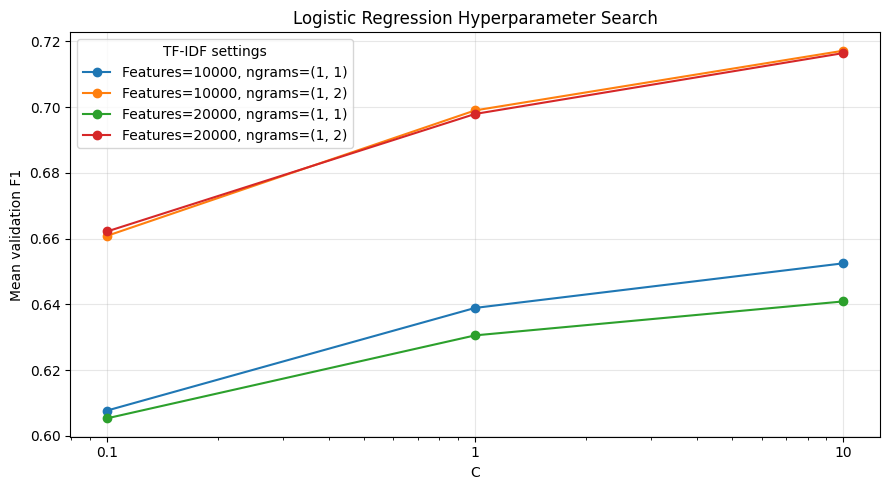

In [23]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

for (max_features, ngram_range), subset in lr_results_table.groupby(
    ["Max Features", "N-gram Range"]
):
    subset = subset.sort_values("C")
    ax.plot(
        subset["C"],
        subset["Mean Validation F1"],
        marker="o",
        label=f"Features={max_features}, ngrams={ngram_range}"
    )

ax.set_xscale("log")
ax.set_xticks([0.1, 1, 10], labels=["0.1", "1", "10"])
ax.set_xlabel("C")
ax.set_ylabel("Mean validation F1")
ax.set_title("Logistic Regression Hyperparameter Search")
ax.legend(title="TF-IDF settings")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Selected parameters

The best Logistic Regression setting was:
- `C = 10`
- `max_features = 10000`
- `ngram_range = (1, 2)`

It gave the highest mean validation F1 out of the 12 combinations. Unigrams + bigrams performed better than unigrams alone, while 20,000 features did not improve the score in this run. The test set was not used during tuning.

## 6. Save the best Logistic Regression model

In [24]:
best_logistic_model = grid_search.best_estimator_

joblib.dump(
    best_logistic_model,
    "best_logistic_regression_model.pkl"
)

print("Best Logistic Regression model saved successfully.")

Best Logistic Regression model saved successfully.


# Support Vector Machine (SVM)

LinearSVC is the second model. It is suitable for high-dimensional sparse text features such as TF-IDF and is commonly used for text classification.

In [25]:
# Check versions
import sys
import pandas as pd
import numpy as np
import sklearn
import joblib
import matplotlib

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)
print("Matplotlib:", matplotlib.__version__)

Python: 3.13.5
pandas: 2.2.3
NumPy: 2.3.5
scikit-learn: 1.8.0
joblib: 1.5.3
Matplotlib: 3.10.8


In [26]:
print("Using halu_train.csv generated in the preprocessing section.")

Using halu_train.csv generated in the preprocessing section.


In [27]:
# Load training data
train_data = pd.read_csv("halu_train.csv")

print("Training shape:", train_data.shape)
print("Columns:", train_data.columns.tolist())

train_data.head(3)

Training shape: (16000, 5)
Columns: ['knowledge', 'question', 'answer', 'label', 'text']


,knowledge,question,answer,label,text
0,Vincenzo Salvatore Carmelo Francesco Bellini (...,"Who has knowledge of more arts, Vincenzo Belli...",Igor Fyodorovich Stravinsky,0,Knowledge: Vincenzo Salvatore Carmelo Francesc...
1,Vincenzo Salvatore Carmelo Francesco Bellini (...,"Who has knowledge of more arts, Vincenzo Belli...",Vincenzo Bellini had more knowledge.,1,Knowledge: Vincenzo Salvatore Carmelo Francesc...
2,"The Naga Chili, closely related to the Bhut jo...","The Naga Chili, closely related to the Bhut jo...",Bangladesh,0,"Knowledge: The Naga Chili, closely related to ..."


In [28]:
# Check missing values, duplicates, and class balance
print("Missing values per column:")
print(train_data.isna().sum())

print("\nDuplicate rows:", train_data.duplicated().sum())

print("\nLabel counts:")
print(train_data["label"].value_counts().sort_index())

print("\nLabel percentages:")
print(
    train_data["label"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

Missing values per column:
knowledge    0
question     0
answer       0
label        0
text         0
dtype: int64

Duplicate rows: 0

Label counts:
label
0    8000
1    8000
Name: count, dtype: int64

Label percentages:
label
0    50.0
1    50.0
Name: proportion, dtype: float64


In [29]:
# Prepare X, y, and question groups
X_train = train_data["text"]
y_train = train_data["label"]
groups = train_data["question"]

print("Training samples:", len(X_train))
print("Unique questions:", groups.nunique())

print("\nNumber of records per question:")
print(groups.value_counts().value_counts().sort_index())

# Check that every question has both labels
labels_per_question = train_data.groupby("question")["label"].agg(set)

assert set(y_train.unique()) == {0, 1}, "Unexpected labels."
assert groups.value_counts().eq(2).all(), "A question does not have two records."
assert labels_per_question.apply(lambda labels: labels == {0, 1}).all(), (
    "A question does not contain both labels."
)

print("\nGroup structure checks passed.")

Training samples: 16000
Unique questions: 8000

Number of records per question:
count
2    8000
Name: count, dtype: int64



Group structure checks passed.


## Data checks before SVM

- Training set: 16,000 instances from 8,000 questions.
- The two classes are balanced.
- No missing values or duplicate rows were found.
- We keep the same train/test split created earlier.
- TF-IDF stays inside the pipeline, so it is fitted separately inside each CV fold.
- GroupKFold keeps both answers from the same question together.
- No extra StandardScaler is needed because TF-IDF already uses L2 normalization.

In [30]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline

# TF-IDF + LinearSVC pipeline
svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2)
    )),
    ("svm", LinearSVC(
        C=1.0,
        max_iter=5000,
        random_state=42
    ))
])

svm_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('tfidf', ...), ('svm', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None


In [31]:
from sklearn.model_selection import GroupKFold

# Grouped CV folds
cv = GroupKFold(n_splits=5)
cv_splits = list(cv.split(X_train, y_train, groups=groups))

for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):
    train_questions = set(groups.iloc[train_idx])
    val_questions = set(groups.iloc[val_idx])

    overlap = train_questions.intersection(val_questions)
    assert len(overlap) == 0, f"Question overlap in fold {fold}."

    print(
        f"Fold {fold}: "
        f"Train = {len(train_idx)}, "
        f"Validation = {len(val_idx)}, "
        f"Shared questions = {len(overlap)}"
    )

Fold 1: Train = 12800, Validation = 3200, Shared questions = 0
Fold 2: Train = 12800, Validation = 3200, Shared questions = 0
Fold 3: Train = 12800, Validation = 3200, Shared questions = 0
Fold 4: Train = 12800, Validation = 3200, Shared questions = 0
Fold 5: Train = 12800, Validation = 3200, Shared questions = 0


In [32]:
# Count both classes
def class_distribution(labels):
    return labels.value_counts().reindex([0, 1], fill_value=0)


# Class counts in each fold
fold_rows = []

for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):
    train_counts = class_distribution(y_train.iloc[train_idx])
    val_counts = class_distribution(y_train.iloc[val_idx])

    fold_rows.append({
        "Fold": fold,
        "Train Faithful (0)": train_counts[0],
        "Train Hallucinated (1)": train_counts[1],
        "Validation Faithful (0)": val_counts[0],
        "Validation Hallucinated (1)": val_counts[1]
    })

fold_distribution = pd.DataFrame(fold_rows)

print("Class distribution in each cross-validation fold:")
display(fold_distribution)

Class distribution in each cross-validation fold:


,Fold,Train Faithful (0),Train Hallucinated (1),Validation Faithful (0),Validation Hallucinated (1)
0,1,6400,6400,1600,1600
1,2,6400,6400,1600,1600
2,3,6400,6400,1600,1600
3,4,6400,6400,1600,1600
4,5,6400,6400,1600,1600


In [33]:
from sklearn.model_selection import cross_validate

# Baseline CV
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

baseline_results = cross_validate(
    estimator=svm_pipeline,
    X=X_train,
    y=y_train,
    cv=cv_splits,
    scoring=scoring,
    n_jobs=2,
    error_score="raise"
)

# Fold scores
baseline_scores = pd.DataFrame({
    metric: baseline_results[f"test_{metric}"]
    for metric in scoring
})
baseline_scores.index = range(1, 6)
baseline_scores.index.name = "Fold"

print("Baseline cross-validation scores:")
print(baseline_scores.round(4))

print("\nMean and standard deviation across folds:")
print(baseline_scores.agg(["mean", "std"]).round(4))

Baseline cross-validation scores:
      accuracy  precision  recall      f1
Fold                                     
1       0.7391     0.7734  0.6762  0.7216
2       0.7256     0.7528  0.6719  0.7100
3       0.7309     0.7561  0.6819  0.7171
4       0.7347     0.7570  0.6912  0.7226
5       0.7262     0.7463  0.6856  0.7147

Mean and standard deviation across folds:
      accuracy  precision  recall      f1
mean    0.7313     0.7571  0.6814  0.7172
std     0.0057     0.0100  0.0076  0.0052


In [34]:
from sklearn.model_selection import ParameterGrid

# Hyperparameter grid
param_grid = {
    "tfidf__max_features": [10000, 20000],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "svm__C": [0.1, 1.0, 10.0]
}

n_combinations = len(list(ParameterGrid(param_grid)))

print("Parameter combinations:", n_combinations)
print("Cross-validation fits:", n_combinations * len(cv_splits))

Parameter combinations: 12
Cross-validation fits: 60


In [35]:
from sklearn.model_selection import GridSearchCV
from time import perf_counter

# Grid search
grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring=scoring,
    refit="f1",
    cv=cv_splits,
    n_jobs=2,
    verbose=1,
    error_score="raise"
)

start_time = perf_counter()
grid_search.fit(X_train, y_train)
elapsed_seconds = perf_counter() - start_time

print(f"\nSearch duration: {elapsed_seconds / 60:.2f} minutes")
print("Best parameters:", grid_search.best_params_)
print(f"Best mean validation F1: {grid_search.best_score_:.4f}")

svm_best_cv_f1 = grid_search.best_score_

Fitting 5 folds for each of 12 candidates, totalling 60 fits



Search duration: 4.85 minutes
Best parameters: {'svm__C': 1.0, 'tfidf__max_features': 20000, 'tfidf__ngram_range': (1, 2)}
Best mean validation F1: 0.7172


In [36]:
# Tuning results table
cv_results = pd.DataFrame(grid_search.cv_results_)

results_table = cv_results[[
    "param_svm__C",
    "param_tfidf__max_features",
    "param_tfidf__ngram_range",
    "mean_test_accuracy",
    "mean_test_precision",
    "mean_test_recall",
    "mean_test_f1",
    "std_test_f1",
    "rank_test_f1"
]].copy()

results_table.columns = [
    "C",
    "Max Features",
    "N-gram Range",
    "Mean Accuracy",
    "Mean Precision",
    "Mean Recall",
    "Mean F1",
    "F1 Std",
    "F1 Rank"
]

results_table = results_table.sort_values(
    ["F1 Rank", "C", "Max Features"]
).reset_index(drop=True)

print("Table 1. SVM hyperparameter combinations ranked by validation F1")
display(results_table.round(4))

Table 1. SVM hyperparameter combinations ranked by validation F1


,C,Max Features,N-gram Range,Mean Accuracy,Mean Precision,Mean Recall,Mean F1,F1 Std,F1 Rank
0,1.0,20000,"(1, 2)",0.7313,0.7571,0.6814,0.7172,0.0046,1
1,1.0,10000,"(1, 2)",0.7296,0.7522,0.6851,0.7170,0.0061,2
2,10.0,20000,"(1, 2)",0.7071,0.7150,0.6891,0.7017,0.0045,3
3,10.0,10000,"(1, 2)",0.6991,0.7021,0.6921,0.6970,0.0053,4
4,0.1,20000,"(1, 2)",0.7191,0.7597,0.6412,0.6954,0.0046,5
5,0.1,10000,"(1, 2)",0.7204,0.7659,0.6354,0.6944,0.0041,6
6,1.0,10000,"(1, 1)",0.6607,0.6707,0.6319,0.6505,0.0091,7
7,1.0,20000,"(1, 1)",0.6600,0.6788,0.6075,0.6411,0.0083,8
8,10.0,10000,"(1, 1)",0.6437,0.6501,0.6228,0.6360,0.0075,9
9,0.1,10000,"(1, 1)",0.6474,0.6582,0.6136,0.6351,0.0044,10


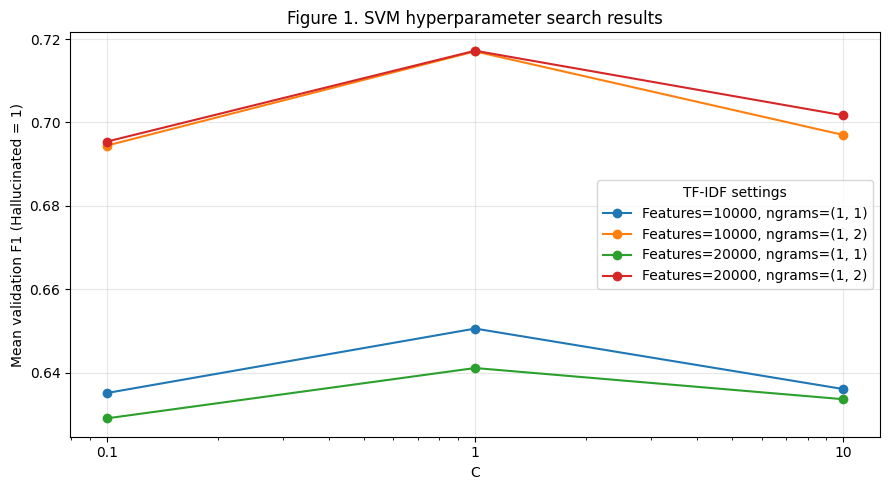

In [37]:
import matplotlib.pyplot as plt

# Plot tuning results
fig, ax = plt.subplots(figsize=(9, 5))

for (max_features, ngram_range), subset in results_table.groupby(
    ["Max Features", "N-gram Range"]
):
    subset = subset.sort_values("C")

    ax.plot(
        subset["C"],
        subset["Mean F1"],
        marker="o",
        label=f"Features={max_features}, ngrams={ngram_range}"
    )

ax.set_xscale("log")
ax.set_xticks([0.1, 1.0, 10.0], labels=["0.1", "1", "10"])
ax.set_xlabel("C")
ax.set_ylabel("Mean validation F1 (Hallucinated = 1)")
ax.set_title("Figure 1. SVM hyperparameter search results")
ax.legend(title="TF-IDF settings")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [38]:
# Scores for the selected setting
best_index = grid_search.best_index_

selected_scores = pd.DataFrame({
    metric: [
        grid_search.cv_results_[f"split{fold}_test_{metric}"][best_index]
        for fold in range(len(cv_splits))
    ]
    for metric in scoring
})

# Compare baseline and tuned SVM
comparison_rows = []

for model_name, scores in [
    ("Baseline SVM", baseline_scores),
    ("Grid-selected SVM", selected_scores)
]:
    for metric in scoring:
        comparison_rows.append({
            "Model": model_name,
            "Metric": metric,
            "Mean": scores[metric].mean(),
            "Std": scores[metric].std(ddof=0)
        })

comparison_table = pd.DataFrame(comparison_rows)

print("Table 2. Baseline and grid-selected SVM validation performance")
display(comparison_table.round(4))

Table 2. Baseline and grid-selected SVM validation performance


,Model,Metric,Mean,Std
0,Baseline SVM,accuracy,0.7313,0.0051
1,Baseline SVM,precision,0.7571,0.0090
2,Baseline SVM,recall,0.6814,0.0068
3,Baseline SVM,f1,0.7172,0.0046
4,Grid-selected SVM,accuracy,0.7313,0.0051
5,Grid-selected SVM,precision,0.7571,0.0090
6,Grid-selected SVM,recall,0.6814,0.0068
7,Grid-selected SVM,f1,0.7172,0.0046


### SVM tuning notes

The best SVM setting was:
- `C = 1.0`
- `max_features = 20000`
- `ngram_range = (1, 2)`

Its mean CV F1 was about **0.7172**. The grid search did not improve over the baseline because the baseline already used this setting.

Unigrams + bigrams performed better than unigrams alone. Precision is higher than recall, so the model avoids false alarms better than it catches every hallucinated answer.

In [39]:
# Save the best SVM
best_svm_pipeline = grid_search.best_estimator_
model_filename = "best_svm_pipeline.pkl"

joblib.dump(best_svm_pipeline, model_filename)

# Check saved model
loaded_pipeline = joblib.load(model_filename)

original_predictions = best_svm_pipeline.predict(X_train.iloc[:5])
loaded_predictions = loaded_pipeline.predict(X_train.iloc[:5])

assert np.array_equal(original_predictions, loaded_predictions), (
    "Predictions changed after saving and loading."
)

print("Saved:", model_filename)
print("Save/load verification passed.")

Saved: best_svm_pipeline.pkl
Save/load verification passed.


# Evaluation and Results

## 1. Setup

The processed train/test files and the two tuned models were created in the previous sections, so they are loaded directly here.

In [40]:
import os
import shutil

import numpy as np
import pandas as pd
import joblib
import sklearn
import matplotlib.pyplot as plt

from scipy.stats import binomtest
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_curve, roc_auc_score
)

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
CLASS_NAMES = ["Faithful (0)", "Hallucinated (1)"]

print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.8.0


The evaluation uses the same train/test files and the two saved pipelines. Tables and figures are saved in the `results` folder.

In [41]:
TRAIN_CSV = "halu_train.csv"
TEST_CSV = "halu_test.csv"
LR_MODEL_FILE = "best_logistic_regression_model.pkl"
SVM_MODEL_FILE = "best_svm_pipeline.pkl"

RESULTS_DIR = "results"
TABLES_DIR = os.path.join(RESULTS_DIR, "tables")
FIGURES_DIR = os.path.join(RESULTS_DIR, "figures")
os.makedirs(TABLES_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

print("Using files created in the previous sections.")

Using files created in the previous sections.


### 1.1 Dataset checks

We check missing values, class balance, the paired-question structure, and question overlap between train and test.

In [42]:
train_data = pd.read_csv(TRAIN_CSV)
test_data = pd.read_csv(TEST_CSV)

print("Train shape:", train_data.shape)
print("Test shape:", test_data.shape)
print("Columns:", test_data.columns.tolist())
print("\nMissing values (test):\n", test_data.isna().sum())

print("\nLabel counts (test):")
print(test_data["label"].value_counts().sort_index())

for name, data in [("train", train_data), ("test", test_data)]:
    assert set(data["label"].unique()) == {0, 1}
    assert data["question"].value_counts().eq(2).all()
    assert data.groupby("question")["label"].agg(set).apply(lambda s: s == {0, 1}).all()

shared_questions = set(train_data["question"]) & set(test_data["question"])
print("\nUnique questions (test):", test_data["question"].nunique())
print("Questions shared between train and test:", len(shared_questions))
print("Structure checks passed.")

Train shape: (16000, 5)
Test shape: (4000, 5)
Columns: ['knowledge', 'question', 'answer', 'label', 'text']

Missing values (test):
 knowledge    0
question     0
answer       0
label        0
text         0
dtype: int64

Label counts (test):
label
0    2000
1    2000
Name: count, dtype: int64



Unique questions (test): 2000
Questions shared between train and test: 0
Structure checks passed.


### 1.2 Load models

Each saved file contains the full TF-IDF + classifier pipeline.

In [43]:
models = {
    "Logistic Regression": joblib.load(LR_MODEL_FILE),
    "SVM (LinearSVC)": joblib.load(SVM_MODEL_FILE),
}

KEY = {"Logistic Regression": "lr", "SVM (LinearSVC)": "svm"}
COLORS = {
    "Logistic Regression": "#4C72B0",
    "SVM (LinearSVC)": "#DD8452",
    "Majority class": "#9A9A9A",
    "Answer length only": "#55A868",
}

MODEL_A = "Logistic Regression"
MODEL_B = "SVM (LinearSVC)"

for name, model in models.items():
    print(f"{name}:")
    for step_name, step in model.steps:
        print(f"   {step_name}: {step}")

Logistic Regression:
   tfidf: TfidfVectorizer(max_features=10000, ngram_range=(1, 2))
   logreg: LogisticRegression(C=10, max_iter=1000, random_state=42)
SVM (LinearSVC):
   tfidf: TfidfVectorizer(max_features=20000, ngram_range=(1, 2))
   svm: LinearSVC(max_iter=5000, random_state=42)


## 2. Predictions

Both models predict the test labels. We also keep a score for each prediction so we can draw ROC curves.

In [44]:
X_train = train_data["text"]
y_train = train_data["label"].to_numpy()
X_test = test_data["text"]
y_test = test_data["label"].to_numpy()

preds, scores = {}, {}

for name, model in models.items():
    preds[name] = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        scores[name] = model.predict_proba(X_test)[:, 1]
    else:
        scores[name] = model.decision_function(X_test)

    print(f"{name}: predicted hallucinated = {(preds[name] == 1).sum()}, "
          f"predicted faithful = {(preds[name] == 0).sum()}")

Logistic Regression: predicted hallucinated = 1807, predicted faithful = 2193


SVM (LinearSVC): predicted hallucinated = 1768, predicted faithful = 2232


## 3. Performance metrics

We report Accuracy, Precision, Recall, F1, and ROC-AUC.

The test set is balanced, so Accuracy is useful. Precision shows how many flagged answers are actually hallucinated, Recall shows how many hallucinated answers are detected, and F1 balances both. F1 is also the score used during tuning.

In [45]:
def evaluate(y_true, y_pred, y_score):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_score),
    }

results = pd.DataFrame(
    {name: evaluate(y_test, preds[name], scores[name]) for name in models}
).T
results.index.name = "Model"

print("Table 1. Test-set performance (positive class = Hallucinated)")
display(results.round(4))

Table 1. Test-set performance (positive class = Hallucinated)


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.7288,0.7532,0.6805,0.7150,0.8040
SVM (LinearSVC),0.7330,0.7636,0.6750,0.7166,0.8072


The classification report is also shown for both classes.

In [46]:
for name, p in preds.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, p, target_names=CLASS_NAMES, digits=4))

Logistic Regression
                  precision    recall  f1-score   support

    Faithful (0)     0.7086    0.7770    0.7412      2000
Hallucinated (1)     0.7532    0.6805    0.7150      2000

        accuracy                         0.7288      4000
       macro avg     0.7309    0.7288    0.7281      4000
    weighted avg     0.7309    0.7288    0.7281      4000

SVM (LinearSVC)
                  precision    recall  f1-score   support

    Faithful (0)     0.7088    0.7910    0.7476      2000
Hallucinated (1)     0.7636    0.6750    0.7166      2000

        accuracy                         0.7330      4000
       macro avg     0.7362    0.7330    0.7321      4000
    weighted avg     0.7362    0.7330    0.7321      4000



We compare training, cross-validation, and test scores to check for overfitting and to see whether the CV results match the final test results.

In [47]:
validation_f1 = {"Logistic Regression": lr_best_cv_f1, "SVM (LinearSVC)": svm_best_cv_f1}

generalisation = pd.DataFrame({
    name: {
        "Validation F1 (CV)": validation_f1.get(name, np.nan),
        "Train F1": f1_score(y_train, models[name].predict(X_train), pos_label=1),
        "Test F1": results.loc[name, "F1-score"],
        "Train accuracy": accuracy_score(y_train, models[name].predict(X_train)),
        "Test accuracy": results.loc[name, "Accuracy"],
    }
    for name in models
}).T
generalisation["Train - Test F1"] = generalisation["Train F1"] - generalisation["Test F1"]
generalisation["Test - CV F1"] = generalisation["Test F1"] - generalisation["Validation F1 (CV)"]
generalisation.index.name = "Model"

print("Table 2. Cross-validation, training and test performance")
display(generalisation.round(4))

Table 2. Cross-validation, training and test performance


,Validation F1 (CV),Train F1,Test F1,Train accuracy,Test accuracy,Train - Test F1,Test - CV F1
Model,,,,,,,
Logistic Regression,0.7171,0.8417,0.7150,0.8474,0.7288,0.1267,-0.0021
SVM (LinearSVC),0.7172,0.8721,0.7166,0.8772,0.7330,0.1556,-0.0006


In [48]:
ranked = results.sort_values(["F1-score", "Recall"], ascending=False)
best_model_name = ranked.index[0]
other_model_name = ranked.index[1]

print("Highest test F1:", best_model_name)

Highest test F1: SVM (LinearSVC)


## 4. Simple baselines

We compare the models with:
1. **Majority class**
2. **Answer length only**

The length-only baseline is included because the two classes have very different answer lengths. This helps us check whether length is acting as a shortcut.

In [49]:
def length_features(df):
    words = df["answer"].str.split().str.len()
    return pd.DataFrame({
        "words": words,
        "log_words": np.log1p(words),
        "chars": df["answer"].str.len(),
    })

baselines = {
    "Majority class": DummyClassifier(strategy="most_frequent"),
    "Answer length only": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
}

train_length = length_features(train_data)
test_length = length_features(test_data)

baseline_preds, baseline_scores = {}, {}

for name, baseline in baselines.items():
    baseline.fit(train_length, y_train)
    baseline_preds[name] = baseline.predict(test_length)
    baseline_scores[name] = baseline.predict_proba(test_length)[:, 1]

all_preds = {**preds, **baseline_preds}
all_scores = {**scores, **baseline_scores}

all_results = pd.DataFrame(
    {name: evaluate(y_test, all_preds[name], all_scores[name]) for name in all_preds}
).T
all_results.index.name = "System"

print("Table 3. Models compared with the baselines on the test set")
display(all_results.round(4))

Table 3. Models compared with the baselines on the test set


,Accuracy,Precision,Recall,F1-score,ROC-AUC
System,,,,,
Logistic Regression,0.7288,0.7532,0.6805,0.7150,0.8040
SVM (LinearSVC),0.7330,0.7636,0.6750,0.7166,0.8072
Majority class,0.5000,0.0000,0.0000,0.0000,0.5000
Answer length only,0.9438,0.9458,0.9415,0.9436,0.9716


## 5. Confusion matrices

The confusion matrices show correct predictions, false positives, and false negatives for each model.

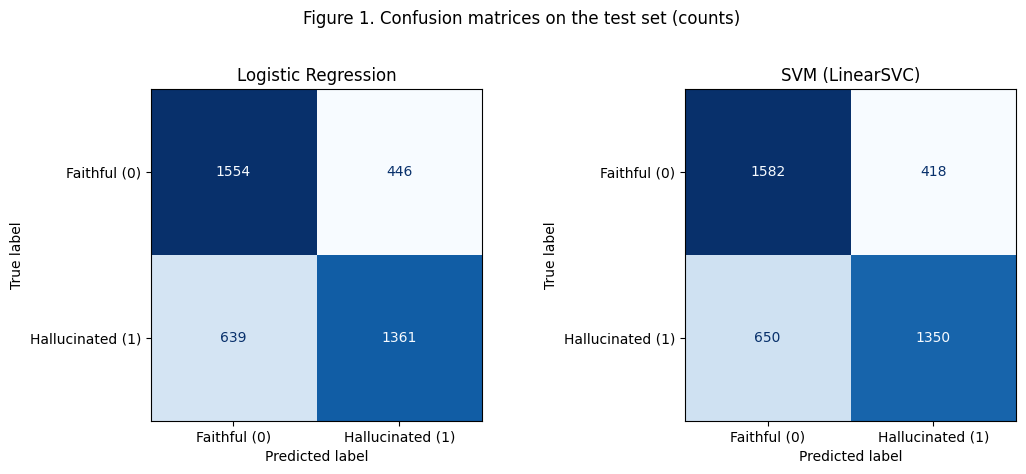

In [50]:
fig, axes = plt.subplots(1, len(models), figsize=(5.5 * len(models), 4.6))

for ax, (name, p) in zip(np.atleast_1d(axes), preds.items()):
    cm = confusion_matrix(y_test, p, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

fig.suptitle("Figure 1. Confusion matrices on the test set (counts)", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "confusion_matrices_counts.png"), dpi=200, bbox_inches="tight")
plt.show()

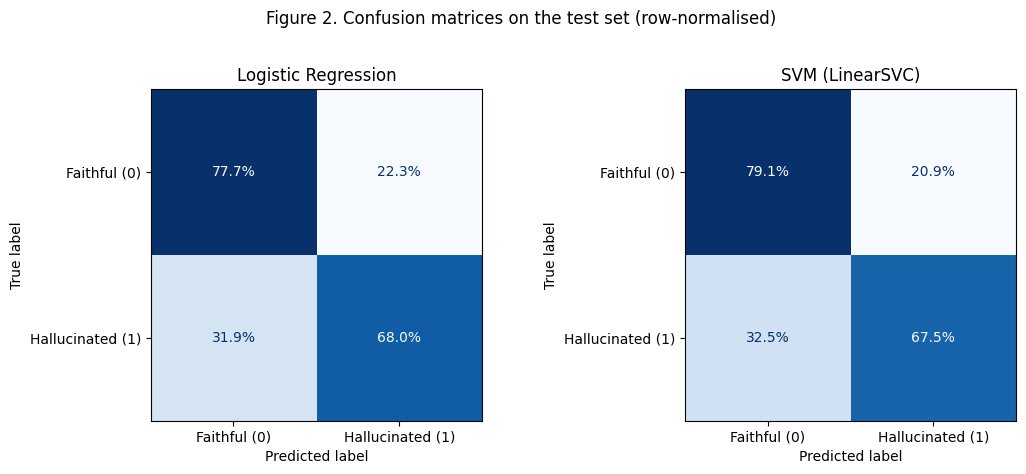

In [51]:
fig, axes = plt.subplots(1, len(models), figsize=(5.5 * len(models), 4.6))

for ax, (name, p) in zip(np.atleast_1d(axes), preds.items()):
    cm_norm = confusion_matrix(y_test, p, labels=[0, 1], normalize="true")
    ConfusionMatrixDisplay(cm_norm, display_labels=CLASS_NAMES).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=".1%"
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

fig.suptitle("Figure 2. Confusion matrices on the test set (row-normalised)", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "confusion_matrices_normalized.png"), dpi=200, bbox_inches="tight")
plt.show()

In [52]:
cm_rows = []
for name, p in preds.items():
    tn, fp, fn, tp = confusion_matrix(y_test, p, labels=[0, 1]).ravel()
    cm_rows.append({
        "Model": name,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "False positive rate": fp / (fp + tn),
        "False negative rate": fn / (fn + tp),
        "Total errors": fp + fn,
    })

cm_table = pd.DataFrame(cm_rows).set_index("Model")

print("Table 4. Confusion matrix values and error rates")
display(cm_table.round(4))

Table 4. Confusion matrix values and error rates


,TN,FP,FN,TP,False positive rate,False negative rate,Total errors
Model,,,,,,,
Logistic Regression,1554,446,639,1361,0.223,0.3195,1085
SVM (LinearSVC),1582,418,650,1350,0.209,0.3250,1068


## 6. Model comparison

The next plots compare the main test metrics, ROC curves, and F1 scores against the baselines.

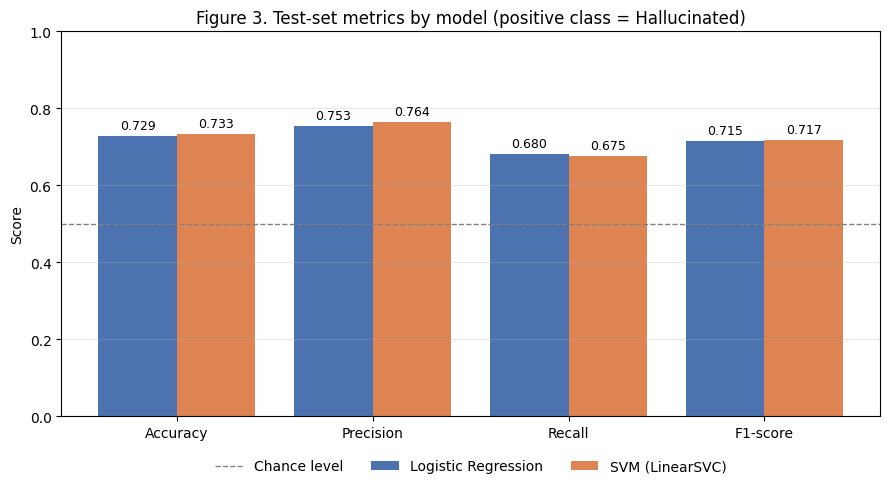

In [53]:
metric_names = ["Accuracy", "Precision", "Recall", "F1-score"]
x = np.arange(len(metric_names))
width = 0.8 / len(models)

fig, ax = plt.subplots(figsize=(9, 5))

for i, name in enumerate(results.index):
    values = results.loc[name, metric_names].to_numpy()
    offset = (i - (len(models) - 1) / 2) * width
    bars = ax.bar(x + offset, values, width, label=name, color=COLORS[name])
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in values], padding=3, fontsize=9)

ax.axhline(0.5, color="gray", linestyle="--", linewidth=1, label="Chance level")
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Figure 3. Test-set metrics by model (positive class = Hallucinated)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "metrics_comparison.png"), dpi=200, bbox_inches="tight")
plt.show()

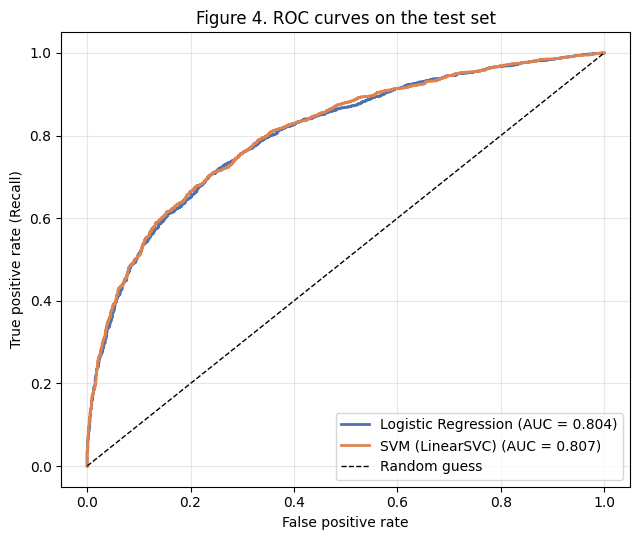

In [54]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))

for name in models:
    fpr, tpr, _ = roc_curve(y_test, scores[name])
    ax.plot(fpr, tpr, label=f"{name} (AUC = {results.loc[name, 'ROC-AUC']:.3f})",
            color=COLORS[name], linewidth=2)

ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random guess")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (Recall)")
ax.set_title("Figure 4. ROC curves on the test set")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "roc_curves.png"), dpi=200, bbox_inches="tight")
plt.show()

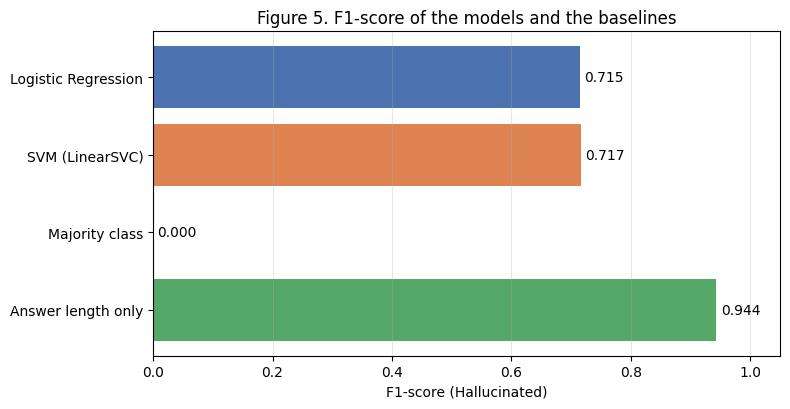

In [55]:
fig, ax = plt.subplots(figsize=(8, 4.2))

names = list(all_results.index)
f1_values = all_results["F1-score"].to_numpy()
bars = ax.barh(names, f1_values, color=[COLORS[n] for n in names])
ax.bar_label(bars, labels=[f"{v:.3f}" for v in f1_values], padding=3)

ax.set_xlim(0, 1.05)
ax.set_xlabel("F1-score (Hallucinated)")
ax.set_title("Figure 5. F1-score of the models and the baselines")
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "models_vs_baselines.png"), dpi=200, bbox_inches="tight")
plt.show()

## 7. Statistical comparison

McNemar's test and question-level bootstrap are used to check whether the small difference between Logistic Regression and SVM is meaningful.

In [56]:
analysis = test_data.copy()
analysis["answer_words"] = analysis["answer"].str.split().str.len()
analysis["knowledge_words"] = analysis["knowledge"].str.split().str.len()

for name in models:
    k = KEY[name]
    analysis[f"pred_{k}"] = preds[name]
    analysis[f"score_{k}"] = scores[name]
    analysis[f"correct_{k}"] = (preds[name] == y_test)

ka, kb = KEY[MODEL_A], KEY[MODEL_B]
only_a_correct = int((analysis[f"correct_{ka}"] & ~analysis[f"correct_{kb}"]).sum())
only_b_correct = int((~analysis[f"correct_{ka}"] & analysis[f"correct_{kb}"]).sum())
n_discordant = only_a_correct + only_b_correct

mcnemar_p = binomtest(min(only_a_correct, only_b_correct), n_discordant, 0.5).pvalue

print(f"Instances where only {MODEL_A} is correct:", only_a_correct)
print(f"Instances where only {MODEL_B} is correct:", only_b_correct)
print(f"McNemar exact test p-value: {mcnemar_p:.4f}")
print("Significant at 0.05" if mcnemar_p < 0.05 else "Not significant at 0.05")

Instances where only Logistic Regression is correct: 132
Instances where only SVM (LinearSVC) is correct: 149
McNemar exact test p-value: 0.3399
Not significant at 0.05


The bootstrap keeps both answers from the same question together during resampling.

In [57]:
count_names = ["tp", "fp", "fn", "ok", "n"]
N_BOOT = 2000

def per_question_counts(y_true, y_pred, questions):
    tmp = pd.DataFrame({
        "question": questions.to_numpy(),
        "tp": ((y_true == 1) & (y_pred == 1)).astype(int),
        "fp": ((y_true == 0) & (y_pred == 1)).astype(int),
        "fn": ((y_true == 1) & (y_pred == 0)).astype(int),
        "ok": (y_true == y_pred).astype(int),
        "n": 1,
    })
    return tmp.groupby("question").sum()

def metrics_from_counts(c):
    tp, fp, fn, ok, n = c["tp"], c["fp"], c["fn"], c["ok"], c["n"]
    return {
        "Accuracy": ok / n,
        "Precision": tp / (tp + fp) if (tp + fp) else 0.0,
        "Recall": tp / (tp + fn) if (tp + fn) else 0.0,
        "F1-score": 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0,
    }

def bootstrap(count_frames, n_boot=N_BOOT, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    arrays = {name: df[count_names].to_numpy() for name, df in count_frames.items()}
    n_q = len(next(iter(arrays.values())))
    out = {name: [] for name in arrays}
    for _ in range(n_boot):
        idx = rng.integers(0, n_q, n_q)
        for name, arr in arrays.items():
            sums = arr[idx].sum(axis=0)
            out[name].append(metrics_from_counts(dict(zip(count_names, sums))))
    return {name: pd.DataFrame(v) for name, v in out.items()}

per_q = {
    name: per_question_counts(y_test, all_preds[name], test_data["question"])
    for name in all_preds
}

boot = bootstrap(per_q)

In [58]:
metric_list = ["Accuracy", "Precision", "Recall", "F1-score"]

ci_rows = []
for name in all_preds:
    point = metrics_from_counts(per_q[name].sum())
    for m in metric_list:
        lo, hi = np.percentile(boot[name][m], [2.5, 97.5])
        ci_rows.append({"System": name, "Metric": m, "Test value": point[m],
                        "95% CI low": lo, "95% CI high": hi})
ci_table = pd.DataFrame(ci_rows)

print("Table 5. Test metrics with 95% bootstrap confidence intervals")
display(ci_table.round(4))

comparisons = [(MODEL_B, MODEL_A), (MODEL_A, "Answer length only"), (MODEL_B, "Answer length only")]

diff_rows = []
for first, second in comparisons:
    p1 = metrics_from_counts(per_q[first].sum())
    p2 = metrics_from_counts(per_q[second].sum())
    for m in metric_list:
        d = boot[first][m] - boot[second][m]
        lo, hi = np.percentile(d, [2.5, 97.5])
        diff_rows.append({
            "Comparison": f"{first} - {second}",
            "Metric": m,
            "Difference (test)": p1[m] - p2[m],
            "95% CI low": lo, "95% CI high": hi,
            "CI contains 0": bool(lo <= 0 <= hi),
        })
diff_table = pd.DataFrame(diff_rows)

print("\nTable 6. Differences between systems")
display(diff_table.round(4))

Table 5. Test metrics with 95% bootstrap confidence intervals


,System,Metric,Test value,95% CI low,95% CI high
0,Logistic Regression,Accuracy,0.7288,0.7167,0.7405
1,Logistic Regression,Precision,0.7532,0.7389,0.7683
2,Logistic Regression,Recall,0.6805,0.6605,0.7010
3,Logistic Regression,F1-score,0.7150,0.7007,0.7285
4,SVM (LinearSVC),Accuracy,0.7330,0.7220,0.7443
5,SVM (LinearSVC),Precision,0.7636,0.7492,0.7787
6,SVM (LinearSVC),Recall,0.6750,0.6545,0.6960
7,SVM (LinearSVC),F1-score,0.7166,0.7031,0.7304
8,Majority class,Accuracy,0.5000,0.5000,0.5000
9,Majority class,Precision,0.0000,0.0000,0.0000



Table 6. Differences between systems


,Comparison,Metric,Difference (test),95% CI low,95% CI high,CI contains 0
0,SVM (LinearSVC) - Logistic Regression,Accuracy,0.0042,-0.0033,0.0115,True
1,SVM (LinearSVC) - Logistic Regression,Precision,0.0104,0.0004,0.0199,False
2,SVM (LinearSVC) - Logistic Regression,Recall,-0.0055,-0.0170,0.0055,True
3,SVM (LinearSVC) - Logistic Regression,F1-score,0.0016,-0.0071,0.0096,True
4,Logistic Regression - Answer length only,Accuracy,-0.2150,-0.2278,-0.2023,False
5,Logistic Regression - Answer length only,Precision,-0.1926,-0.2095,-0.1749,False
6,Logistic Regression - Answer length only,Recall,-0.2610,-0.2825,-0.2380,False
7,Logistic Regression - Answer length only,F1-score,-0.2286,-0.2437,-0.2139,False
8,SVM (LinearSVC) - Answer length only,Accuracy,-0.2108,-0.2233,-0.1980,False
9,SVM (LinearSVC) - Answer length only,Precision,-0.1822,-0.1996,-0.1644,False


## 8. Length-controlled check

To test the answer-length shortcut, we also evaluate questions where the faithful and hallucinated answers differ by at most 3 words. Other thresholds are shown as a sensitivity check.

In [59]:
LENGTH_DIFF_MAX = 3

len_piv = analysis.pivot(index="question", columns="label", values="answer_words")
length_gap = (len_piv[1] - len_piv[0]).abs()

subset_questions = length_gap.index[length_gap <= LENGTH_DIFF_MAX]
print(f"Questions with an answer-length difference of at most {LENGTH_DIFF_MAX} words: "
      f"{len(subset_questions)} of {len(length_gap)} ({len(subset_questions) / len(length_gap):.1%})")

subset_frames = {name: per_q[name].loc[subset_questions] for name in all_preds}
subset_boot = bootstrap(subset_frames)

controlled_rows = []
for name in all_preds:
    point = metrics_from_counts(subset_frames[name].sum())
    lo, hi = np.percentile(subset_boot[name]["F1-score"], [2.5, 97.5])
    controlled_rows.append({
        "System": name,
        "Accuracy": point["Accuracy"],
        "Precision": point["Precision"],
        "Recall": point["Recall"],
        "F1-score": point["F1-score"],
        "F1 95% CI low": lo,
        "F1 95% CI high": hi,
        "F1 (all questions)": metrics_from_counts(per_q[name].sum())["F1-score"],
    })
controlled_table = pd.DataFrame(controlled_rows).set_index("System")
controlled_table["F1 change"] = controlled_table["F1-score"] - controlled_table["F1 (all questions)"]

print(f"\nTable 7. Performance on the length-controlled subset (n = {len(subset_questions)} questions)")
display(controlled_table.round(4))

Questions with an answer-length difference of at most 3 words: 332 of 2000 (16.6%)



Table 7. Performance on the length-controlled subset (n = 332 questions)


,Accuracy,Precision,Recall,F1-score,F1 95% CI low,F1 95% CI high,F1 (all questions),F1 change
System,,,,,,,,
Logistic Regression,0.6295,0.6617,0.5301,0.5886,0.5520,0.6242,0.7150,-0.1264
SVM (LinearSVC),0.6190,0.6502,0.5151,0.5748,0.5374,0.6095,0.7166,-0.1418
Majority class,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Answer length only,0.7651,0.8465,0.6476,0.7338,0.6969,0.7695,0.9436,-0.2098


In [60]:
sensitivity_rows = []

for threshold in [1, 2, 3, 5, None]:
    if threshold is None:
        qs = length_gap.index
        label = "All questions"
    else:
        qs = length_gap.index[length_gap <= threshold]
        label = f"Length difference <= {threshold} words"
    row = {"Subset": label, "Questions": len(qs)}
    for name in all_preds:
        row[name] = metrics_from_counts(per_q[name].loc[qs].sum())["F1-score"]
    sensitivity_rows.append(row)

sensitivity_table = pd.DataFrame(sensitivity_rows).set_index("Subset")

print("Table 8. F1-score under different length-difference thresholds (sensitivity check)")
display(sensitivity_table.round(4))

Table 8. F1-score under different length-difference thresholds (sensitivity check)


,Questions,Logistic Regression,SVM (LinearSVC),Majority class,Answer length only
Subset,,,,,
Length difference <= 1 words,102,0.5106,0.5217,0.0,0.3862
Length difference <= 2 words,185,0.5681,0.5714,0.0,0.5724
Length difference <= 3 words,332,0.5886,0.5748,0.0,0.7338
Length difference <= 5 words,733,0.6402,0.6323,0.0,0.8756
All questions,2000,0.7150,0.7166,0.0,0.9436


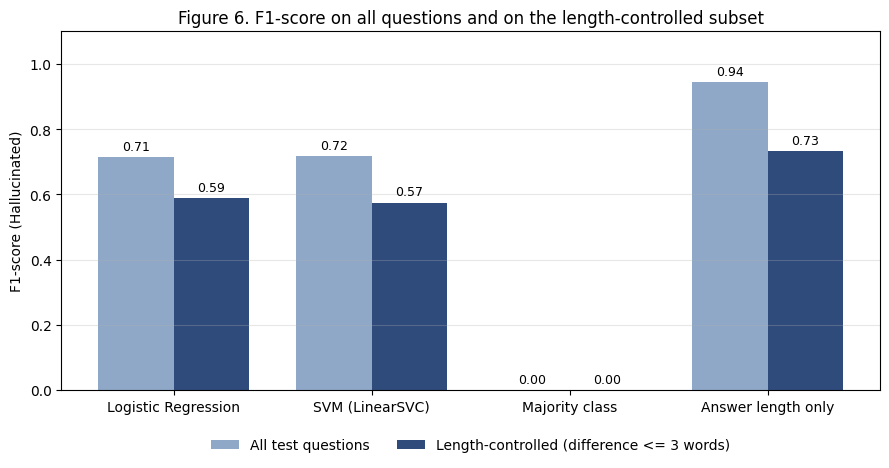

In [61]:
fig, ax = plt.subplots(figsize=(9, 4.8))

names = list(controlled_table.index)
x = np.arange(len(names))
w = 0.38

full = controlled_table["F1 (all questions)"].to_numpy()
controlled = controlled_table["F1-score"].to_numpy()

b1 = ax.bar(x - w / 2, full, w, label="All test questions", color="#8FA8C8")
b2 = ax.bar(x + w / 2, controlled, w, label=f"Length-controlled (difference <= {LENGTH_DIFF_MAX} words)", color="#2F4B7C")
ax.bar_label(b1, labels=[f"{v:.2f}" for v in full], padding=3, fontsize=9)
ax.bar_label(b2, labels=[f"{v:.2f}" for v in controlled], padding=3, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylim(0, 1.1)
ax.set_ylabel("F1-score (Hallucinated)")
ax.set_title("Figure 6. F1-score on all questions and on the length-controlled subset")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "length_controlled_f1.png"), dpi=200, bbox_inches="tight")
plt.show()

## 9. Error analysis

### 9.1 Agreement between the models

In [62]:
agreement = pd.Series({
    "Both correct": int((analysis[f"correct_{ka}"] & analysis[f"correct_{kb}"]).sum()),
    "Both wrong": int((~analysis[f"correct_{ka}"] & ~analysis[f"correct_{kb}"]).sum()),
    f"Only {MODEL_A} correct": only_a_correct,
    f"Only {MODEL_B} correct": only_b_correct,
}, name="Instances")

agreement_table = agreement.to_frame()
agreement_table["Share of test set"] = agreement_table["Instances"] / len(analysis)

print("Table 9. Agreement between the two compared models")
display(agreement_table.round(4))

Table 9. Agreement between the two compared models


,Instances,Share of test set
Both correct,2783,0.6958
Both wrong,936,0.2340
Only Logistic Regression correct,132,0.0330
Only SVM (LinearSVC) correct,149,0.0372


### 9.2 Question-level analysis

Each question has one faithful and one hallucinated answer, so we check the result for each pair and whether the hallucinated answer receives the higher model score.

In [63]:
pair_rows = []
rank_rows = []

for name in models:
    k = KEY[name]
    piv = analysis.pivot(index="question", columns="label", values=[f"pred_{k}", f"score_{k}"])

    pred_h, pred_f = piv[(f"pred_{k}", 1)], piv[(f"pred_{k}", 0)]
    score_h, score_f = piv[(f"score_{k}", 1)], piv[(f"score_{k}", 0)]

    n_q = len(piv)
    pair_rows.append({
        "Model": name,
        "Both right": ((pred_h == 1) & (pred_f == 0)).sum() / n_q,
        "Both flagged hallucinated": ((pred_h == 1) & (pred_f == 1)).sum() / n_q,
        "Both accepted as faithful": ((pred_h == 0) & (pred_f == 0)).sum() / n_q,
        "Swapped": ((pred_h == 0) & (pred_f == 1)).sum() / n_q,
    })
    rank_rows.append({
        "Model": name,
        "Pairwise ranking accuracy": (score_h > score_f).mean(),
    })

pair_table = pd.DataFrame(pair_rows).set_index("Model")
rank_table = pd.DataFrame(rank_rows).set_index("Model")

print("Table 10. Outcome per question (share of the 2,000 test questions)")
display(pair_table.round(4))

print("\nTable 11. Pairwise ranking accuracy")
display(rank_table.round(4))

Table 10. Outcome per question (share of the 2,000 test questions)


,Both right,Both flagged hallucinated,Both accepted as faithful,Swapped
Model,,,,
Logistic Regression,0.473,0.2075,0.304,0.0155
SVM (LinearSVC),0.480,0.1950,0.311,0.0140



Table 11. Pairwise ranking accuracy


,Pairwise ranking accuracy
Model,
Logistic Regression,0.9135
SVM (LinearSVC),0.9175


### 9.3 Effect of answer length

We compare answer length across the two classes and check model error rates for different length groups.

In [64]:
print("Average length in words, by true label:")
display(analysis.groupby("label")[["answer_words", "knowledge_words"]].agg(["mean", "median"]).round(1))

longer = (len_piv[1] > len_piv[0]).mean()
equal = (len_piv[1] == len_piv[0]).mean()
shorter = (len_piv[1] < len_piv[0]).mean()
print(f"\nPer question, the hallucinated answer is longer than the faithful one in {longer:.1%} of questions "
      f"(equal length: {equal:.1%}, shorter: {shorter:.1%}).")

analysis["answer_len_bin"] = pd.qcut(analysis["answer_words"], 5, duplicates="drop")

def length_summary(g):
    row = {"Instances": len(g), "True hallucinated (%)": 100 * g["label"].mean()}
    for name in models:
        k = KEY[name]
        row[f"{name} error rate (%)"] = 100 * (1 - g[f"correct_{k}"].mean())
        row[f"{name} flagged hallucinated (%)"] = 100 * g[f"pred_{k}"].mean()
    return pd.Series(row)

length_table = analysis.groupby("answer_len_bin", observed=True).apply(length_summary, include_groups=False)
length_table.index = length_table.index.astype(str)
length_table.index.name = "Answer length (words)"

print("\nTable 12. Errors by answer length (quintiles)")
display(length_table.round(1))

Average length in words, by true label:


answer_words        knowledge_words       
              mean median            mean median
label                                           
0              2.3    2.0            55.0   51.0
1             10.9    9.0            55.0   51.0


Per question, the hallucinated answer is longer than the faithful one in 96.5% of questions (equal length: 2.4%, shorter: 1.1%).

Table 12. Errors by answer length (quintiles)


,Instances,True hallucinated (%),Logistic Regression error rate (%),Logistic Regression flagged hallucinated (%),SVM (LinearSVC) error rate (%),SVM (LinearSVC) flagged hallucinated (%)
Answer length (words),,,,,,
"(0.999, 2.0]",1435.0,3.3,22.2,20.9,20.6,19.3
"(2.0, 3.0]",411.0,5.8,24.3,26.3,23.4,24.3
"(3.0, 6.0]",659.0,70.0,39.5,48.1,41.0,47.2
"(6.0, 11.0]",735.0,98.1,31.6,67.9,31.0,68.7
"(11.0, 81.0]",760.0,98.2,23.0,76.7,23.6,75.7


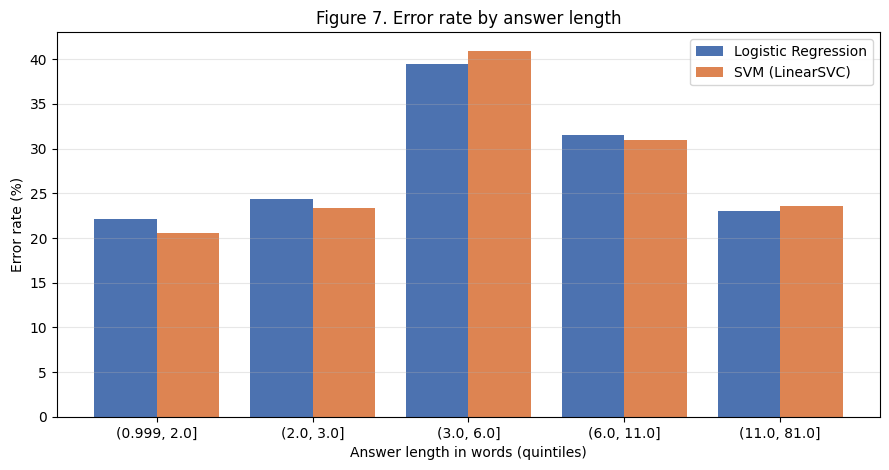

In [65]:
fig, ax = plt.subplots(figsize=(9, 4.8))

bins = length_table.index
x = np.arange(len(bins))
w = 0.8 / len(models)

for i, name in enumerate(models):
    offset = (i - (len(models) - 1) / 2) * w
    ax.bar(x + offset, length_table[f"{name} error rate (%)"], w, label=name, color=COLORS[name])

ax.set_xticks(x)
ax.set_xticklabels(bins)
ax.set_xlabel("Answer length in words (quintiles)")
ax.set_ylabel("Error rate (%)")
ax.set_title("Figure 7. Error rate by answer length")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "error_rate_by_answer_length.png"), dpi=200, bbox_inches="tight")
plt.show()

### 9.4 Effect of question type

Questions are grouped by their first word to see whether some question types are harder than others.

In [66]:
def question_type(q):
    words = q.strip().lower().split()
    first = words[0] if words else ""
    for t in ["who", "what", "when", "where", "which", "how", "why"]:
        if first.startswith(t):
            return t
    return "other (yes/no, etc.)"

analysis["question_type"] = analysis["question"].apply(question_type)

def type_summary(g):
    row = {"Instances": len(g)}
    for name in models:
        row[f"{name} error rate (%)"] = 100 * (1 - g[f"correct_{KEY[name]}"].mean())
    return pd.Series(row)

qtype_table = analysis.groupby("question_type").apply(type_summary, include_groups=False)
qtype_table = qtype_table.sort_values("Instances", ascending=False)
qtype_table["Instances"] = qtype_table["Instances"].astype(int)

print("Table 13. Errors by question type")
display(qtype_table.round(1))

Table 13. Errors by question type


,Instances,Logistic Regression error rate (%),SVM (LinearSVC) error rate (%)
question_type,,,
"other (yes/no, etc.)",1952,26.9,26.6
what,926,27.4,26.7
which,512,30.7,30.5
who,336,25.3,25.6
when,116,22.4,19.8
where,88,19.3,18.2
how,70,28.6,28.6


### 9.5 Misclassified examples

We show a few false negatives and false positives from the model with the highest test F1.

In [67]:
k = KEY[best_model_name]

false_negatives = analysis[(analysis["label"] == 1) & (analysis[f"pred_{k}"] == 0)]
false_positives = analysis[(analysis["label"] == 0) & (analysis[f"pred_{k}"] == 1)]

def show_examples(df, title, n=4):
    print("=" * 90)
    print(f"{title} ({best_model_name}) - showing {n} of {len(df)}")
    print("=" * 90)
    for _, r in df.sample(n, random_state=RANDOM_STATE).iterrows():
        print(f"Question : {r['question'][:200]}")
        print(f"Answer   : {r['answer'][:200]}")
        print(f"Knowledge: {r['knowledge'][:250]}...")
        print(f"Model score: {r[f'score_{k}']:.3f}")
        print("-" * 90)

show_examples(false_negatives, "FALSE NEGATIVES: hallucinated answers accepted as faithful")
show_examples(false_positives, "FALSE POSITIVES: faithful answers flagged as hallucinated")

FALSE NEGATIVES: hallucinated answers accepted as faithful (SVM (LinearSVC)) - showing 4 of 650
Question : What team did Pete Elezovic play for that joined the AFL?
Answer   : Pete Elezovic played for Buffalo Destroyers.
Knowledge: Peter Elezovic (born June 28, 1971) is a former American football placekicker who played seven seasons in the Arena Football League with the Albany Firebirds, Chicago Rush, Buffalo Destroyers, Carolina Cobras, Tampa Bay Storm and New York Dragons. Th...
Model score: -0.372
------------------------------------------------------------------------------------------
Question : Sleigh Ride is a piece of music written by composer described by whom as "one of the great American masters of light orchestral music"?
Answer   : Leroy Anderson described John Williams as a great American composer.
Knowledge: "Sleigh Ride" is a popular light orchestral Christmas music standard composed by Leroy Anderson. John Williams described him as "one of the great American masters of

We also check how much of each answer overlaps with the knowledge text.

In [68]:
def overlap_ratio(row):
    ans = set(row["answer"].lower().split())
    kn = set(row["knowledge"].lower().split())
    return len(ans & kn) / len(ans) if ans else 0.0

analysis["answer_in_knowledge"] = analysis.apply(overlap_ratio, axis=1)

print("Share of answer words that also appear in the knowledge, by true label:")
display(analysis.groupby("label")["answer_in_knowledge"].agg(["mean", "median"]).round(3))

print("\nSame measure for correct and wrong predictions of the best model:")
display(analysis.groupby(f"correct_{k}")["answer_in_knowledge"].agg(["mean", "median", "count"]).round(3))

Share of answer words that also appear in the knowledge, by true label:


,mean,median
label,,
0,0.690,1.000
1,0.533,0.559



Same measure for correct and wrong predictions of the best model:


,mean,median,count
correct_svm,,,
False,0.597,0.625,1068
True,0.617,0.667,2932


## 10. Best model

The model with the highest test F1 is selected, then we check whether its advantage over the other model is statistically meaningful.

In [69]:
winner_rows = []
for m in ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]:
    row = {"Metric": m}
    for name in models:
        row[name] = results.loc[name, m]
    row["Winner"] = results[m].idxmax()
    winner_rows.append(row)
winner_table = pd.DataFrame(winner_rows).set_index("Metric")

print("Table 14. Winner by metric among the trained models")
display(winner_table.round(4))

pair_diff = diff_table[(diff_table["Comparison"] == f"{MODEL_B} - {MODEL_A}") & (diff_table["Metric"] == "F1-score")].iloc[0]
print(f"Highest test F1: {best_model_name} = {results.loc[best_model_name, 'F1-score']:.4f}")
print(f"F1 difference ({MODEL_B} - {MODEL_A}): {pair_diff['Difference (test)']:.4f}")
print(f"95% bootstrap CI of the difference: [{pair_diff['95% CI low']:.4f}, {pair_diff['95% CI high']:.4f}]")
print(f"McNemar exact test p-value: {mcnemar_p:.4f}")

if mcnemar_p < 0.05:
    print("The difference between the models is statistically significant.")
else:
    print("The difference between the models is not statistically significant: they are statistically tied.")

baseline_f1 = all_results.loc["Answer length only", "F1-score"]
best_f1 = results.loc[best_model_name, "F1-score"]
print(f"\nAnswer-length baseline F1: {baseline_f1:.4f}")
print(f"{best_model_name} F1: {best_f1:.4f}")

if best_f1 > baseline_f1:
    print("The selected model outperforms the answer-length baseline.")
else:
    print("The selected model does NOT outperform the answer-length baseline.")

Table 14. Winner by metric among the trained models


,Logistic Regression,SVM (LinearSVC),Winner
Metric,,,
Accuracy,0.7288,0.7330,SVM (LinearSVC)
Precision,0.7532,0.7636,SVM (LinearSVC)
Recall,0.6805,0.6750,Logistic Regression
F1-score,0.7150,0.7166,SVM (LinearSVC)
ROC-AUC,0.8040,0.8072,SVM (LinearSVC)


Highest test F1: SVM (LinearSVC) = 0.7166
F1 difference (SVM (LinearSVC) - Logistic Regression): 0.0016
95% bootstrap CI of the difference: [-0.0071, 0.0096]
McNemar exact test p-value: 0.3399
The difference between the models is not statistically significant: they are statistically tied.

Answer-length baseline F1: 0.9436
SVM (LinearSVC) F1: 0.7166
The selected model does NOT outperform the answer-length baseline.


## 11. Save results

The tables, figures, and test predictions are saved in the `results` folder.

In [70]:
results.round(4).to_csv(os.path.join(TABLES_DIR, "model_comparison.csv"))
generalisation.round(4).to_csv(os.path.join(TABLES_DIR, "train_validation_test_performance.csv"))
all_results.round(4).to_csv(os.path.join(TABLES_DIR, "models_vs_baselines.csv"))
cm_table.round(4).to_csv(os.path.join(TABLES_DIR, "confusion_matrix_summary.csv"))
ci_table.round(4).to_csv(os.path.join(TABLES_DIR, "bootstrap_confidence_intervals.csv"), index=False)
diff_table.round(4).to_csv(os.path.join(TABLES_DIR, "bootstrap_differences.csv"), index=False)
controlled_table.round(4).to_csv(os.path.join(TABLES_DIR, "length_controlled_results.csv"))
sensitivity_table.round(4).to_csv(os.path.join(TABLES_DIR, "length_threshold_sensitivity.csv"))
agreement_table.round(4).to_csv(os.path.join(TABLES_DIR, "model_agreement.csv"))
pair_table.round(4).to_csv(os.path.join(TABLES_DIR, "question_level_outcomes.csv"))
length_table.round(2).to_csv(os.path.join(TABLES_DIR, "errors_by_answer_length.csv"))
qtype_table.round(2).to_csv(os.path.join(TABLES_DIR, "errors_by_question_type.csv"))

prediction_columns = ["question", "answer", "label"] + [
    f"{prefix}_{KEY[name]}" for name in models for prefix in ("pred", "score")
]
analysis[prediction_columns].to_csv(os.path.join(TABLES_DIR, "test_predictions.csv"), index=False)

print("Saved tables:", sorted(os.listdir(TABLES_DIR)))
print("Saved figures:", sorted(os.listdir(FIGURES_DIR)))

shutil.make_archive("results", "zip", RESULTS_DIR)
print("Created results.zip")

Saved tables: ['bootstrap_confidence_intervals.csv', 'bootstrap_differences.csv', 'confusion_matrix_summary.csv', 'errors_by_answer_length.csv', 'errors_by_question_type.csv', 'length_controlled_results.csv', 'length_threshold_sensitivity.csv', 'model_agreement.csv', 'model_comparison.csv', 'models_vs_baselines.csv', 'question_level_outcomes.csv', 'test_predictions.csv', 'train_validation_test_performance.csv']
Saved figures: ['confusion_matrices_counts.png', 'confusion_matrices_normalized.png', 'error_rate_by_answer_length.png', 'length_controlled_f1.png', 'metrics_comparison.png', 'models_vs_baselines.png', 'roc_curves.png']


Created results.zip


## 12. Final summary

| System | Accuracy | Precision | Recall | F1-score | F1 on length-controlled subset |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 0.7288 | 0.7532 | **0.6805** | 0.7150 | **0.5886** |
| **SVM (LinearSVC)** | **0.7330** | **0.7636** | 0.6750 | **0.7166** | 0.5748 |
| Majority class baseline | 0.5000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| Answer-length-only baseline | 0.9438 | 0.9458 | 0.9415 | 0.9436 | 0.7338 |

- SVM has the highest F1 (**0.7166**), but Logistic Regression is very close (**0.7150**).
- The difference is small and not statistically significant (`p = 0.3399`).
- SVM has **418 false positives** and **650 false negatives**, so it misses more hallucinated answers than it falsely flags faithful answers.
- Faithful answers average about **2.3 words**, while hallucinated answers average about **10.9 words**.
- In **96.5%** of test questions, the hallucinated answer is longer.
- The length-only baseline reaches **0.9436 F1**, which shows that answer length is a strong shortcut in this dataset.
- On the length-controlled subset, both trained models drop below **0.60 F1**.

The two trained models are close, and SVM is selected only because it has the slightly higher test F1. The main issue found in the data is the strong answer-length bias, which can be addressed in later improvement work.